# 基于SHAP可解释性的信用违约预测研究

## 1. 问题背景
信用卡违约预测是银行风控的核心问题。传统评分卡模型可解释性强但预测能力有限，机器学习模型预测能力强但“黑箱”特性难以被监管接受。本研究旨在用SHAP方法在两者之间找到平衡。

## 2. 数据与方法
- 数据集：UCI台湾信用卡违约数据集（30000条，23个特征）
- 模型：XGBoost / LightGBM
- 解释方法：SHAP值分析

## 3. 实验设计
- 数据清洗与特征工程
- 模型训练与评估：
  准确率：81.72%
  AUC：0.776
  违约类别 F1：0.47

![ROC曲线](roc_curve.png)
- SHAP全局解释（特征重要性）
- SHAP局部解释（单个样本的预测原因）
**高风险客户力导向图：**

![高风险客户](shap_force_high_risk.png)

**低风险客户力导向图：**

![低风险客户](shap_force_low_risk.png)

## 4. 结果与讨论

### 4.1 主要结论

1. **XGBoost模型在信用违约预测上表现良好**：准确率81.72%，AUC 0.776，能够有效区分违约与不违约客户。

2. **PAY_0（最近一个月还款状态）是最强预测特征**：SHAP全局重要性排名第一。延迟还款行为会显著推高违约概率（高风险客户PAY_0=3，SHAP值大幅为正）。

3. **LIMIT_BAL（信用额度）是第二强特征**：低信用额度推高违约概率（高风险客户额度仅1万，SHAP值正向贡献显著）；高信用额度降低违约概率（低风险客户额度48万，SHAP值负向贡献显著）。

4. **SHAP方法揭示了特征的非线性影响**：传统评分卡模型只能给出线性权重，而SHAP蜂群图显示PAY_0在取值为-2、0、3时对违约概率的影响是非线性的。

### 4.2 方法优势

- **全局解释**：SHAP柱状图和蜂群图揭示了特征重要性和影响方向。
- **局部解释**：SHAP力导向图可以解释单个客户的预测原因，满足监管对"可解释性"的要求。
- **模型对比**：高风险与低风险客户的对比，证明模型决策逻辑清晰、可复现。

### 4.3 局限性与未来工作

- 数据集样本量有限（30000条），模型泛化能力待验证。
- 未进行特征工程（如特征交互、WOE编码）。
- 未来可尝试用SHAP做特征选择，或对比LightGBM等模型的可解释性。
## 5. 结论

本研究基于 UCI 台湾信用卡违约数据集（30000 条，23 个特征），使用 XGBoost 构建信用违约预测模型，并利用 SHAP 方法进行全局和局部可解释性分析。主要结论如下：

1. **模型性能良好**：XGBoost 模型在测试集上准确率达到 81.72%，AUC 为 0.776，能够有效区分违约与不违约客户。

2. **PAY_0 是最强预测特征**：SHAP 全局重要性排名第一。延迟还款行为会显著推高违约概率，高风险客户的 PAY_0=3（延迟3个月），SHAP 值大幅为正。

3. **LIMIT_BAL 是第二强特征**：低信用额度推高违约概率（高风险客户额度仅1万），高信用额度降低违约概率（低风险客户额度48万）。

4. **SHAP 方法兼具预测能力与可解释性**：全局解释揭示了特征重要性排名，局部解释（力导向图）能够清晰说明单个客户被判定为违约或非违约的具体原因，满足金融监管对模型可解释性的要求。

5. **高低风险客户对比验证了模型决策逻辑**：高风险客户（预测值 +2.58）与低风险客户（预测值 -4.11）的预测值差距达 6.69，证明模型判别能力可靠、决策逻辑清晰可复现。

综上，SHAP 方法在保持机器学习模型预测能力的同时，有效解决了传统"黑箱"模型难以被监管接受的问题，为信用违约预测提供了一条兼顾准确性与可解释性的技术路径。

In [16]:
import pandas as pd
df = pd.read_excel('default of credit card clients.xls', header=1)

In [17]:
import pandas as pd

df = pd.read_excel('default of credit card clients.xls', header=1)
df.head()
df.info()
df.describe()
df.shape
print(df.head())
print(df.info())
print(df.describe())
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [18]:
df['default payment next month'].value_counts()
df['default payment next month'].value_counts(normalize=True)

default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

In [19]:

df.groupby('default payment next month')['LIMIT_BAL'].mean()

default payment next month
0    178099.726074
1    130109.656420
Name: LIMIT_BAL, dtype: float64

In [20]:
df.groupby('default payment next month')['AGE'].mean()


default payment next month
0    35.417266
1    35.725738
Name: AGE, dtype: float64

In [21]:
df.groupby('default payment next month')['SEX'].mean()

default payment next month
0    1.614150
1    1.567058
Name: SEX, dtype: float64

In [22]:
df.groupby('default payment next month')['PAY_0'].mean()

default payment next month
0   -0.211222
1    0.668174
Name: PAY_0, dtype: float64

## 9月26日：数据探索

- 数据量：30000 行，25 列
- 违约率：22.12%（类别不平衡，不违约 77.88%）
- 关键发现：
  - 违约客户平均信用额度（13万）显著低于不违约客户（17.9万）
  - 年龄和性别在违约与不违约客户间几乎无差异
  - PAY_0（最近还款状态）差异巨大：不违约 -0.21 vs 违约 0.67
  - PAY_0 和 LIMIT_BAL 是强预测变量
- 评估标准：不能只看准确率，要用 AUC 和召回率

In [23]:

y = df['default payment next month']

X = df.drop(columns=['ID', 'default payment next month'])

print("特征数量：", X.shape[1])
print("样本数量：", X.shape[0])

特征数量： 23
样本数量： 30000


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [25]:
from sklearn import set_config
set_config(display='text')

In [26]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [27]:
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

print("准确率：", accuracy_score(y_test, y_pred))
print("AUC：", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))

准确率： 0.8171666666666667
AUC： 0.7756557697855742
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.65      0.37      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000



In [28]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

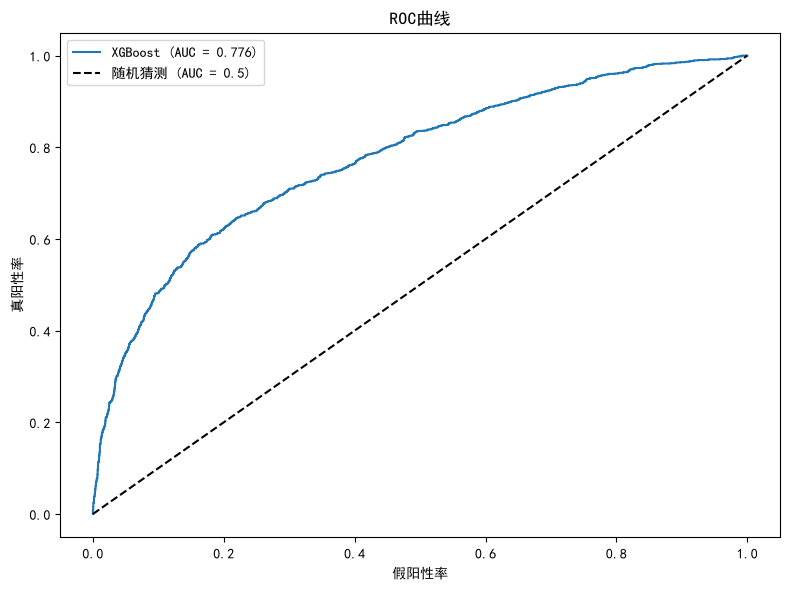

In [29]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='随机猜测 (AUC = 0.5)')
plt.xlabel('假阳性率')
plt.ylabel('真阳性率')
plt.title('ROC曲线')
plt.legend()
plt.tight_layout()
plt.savefig('roc_curve.png')
plt.show()

In [30]:
import shap
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test.iloc[:500])

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

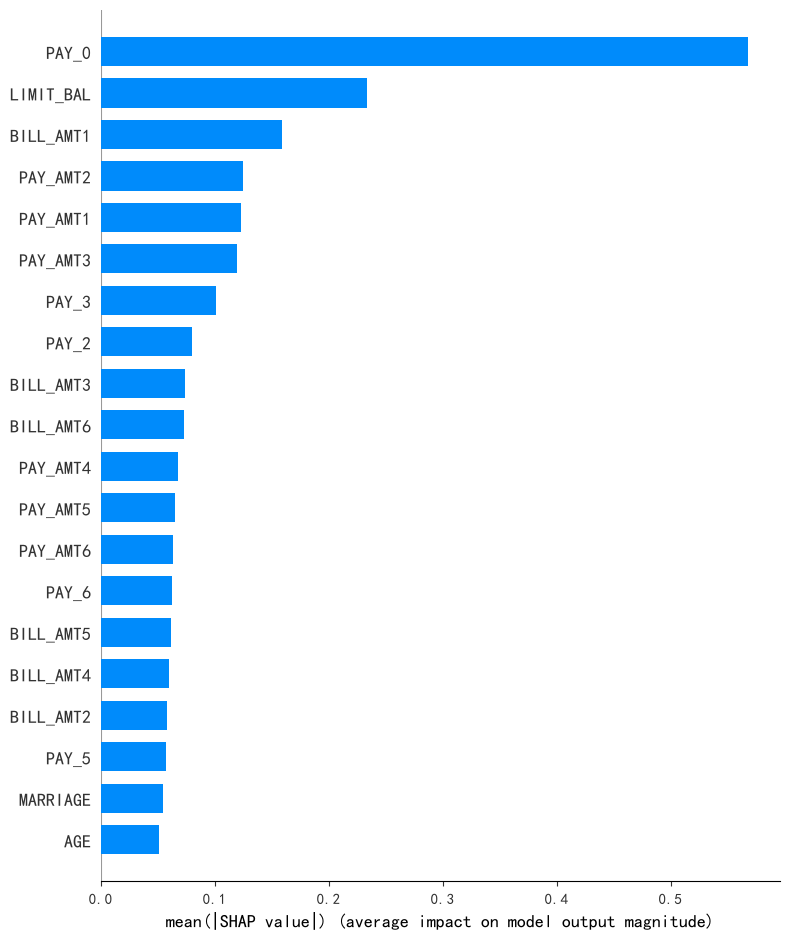

In [32]:
shap.summary_plot(shap_values, X_test.iloc[:500], plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('shap_global_importance.png', bbox_inches='tight', dpi=150)
plt.show()

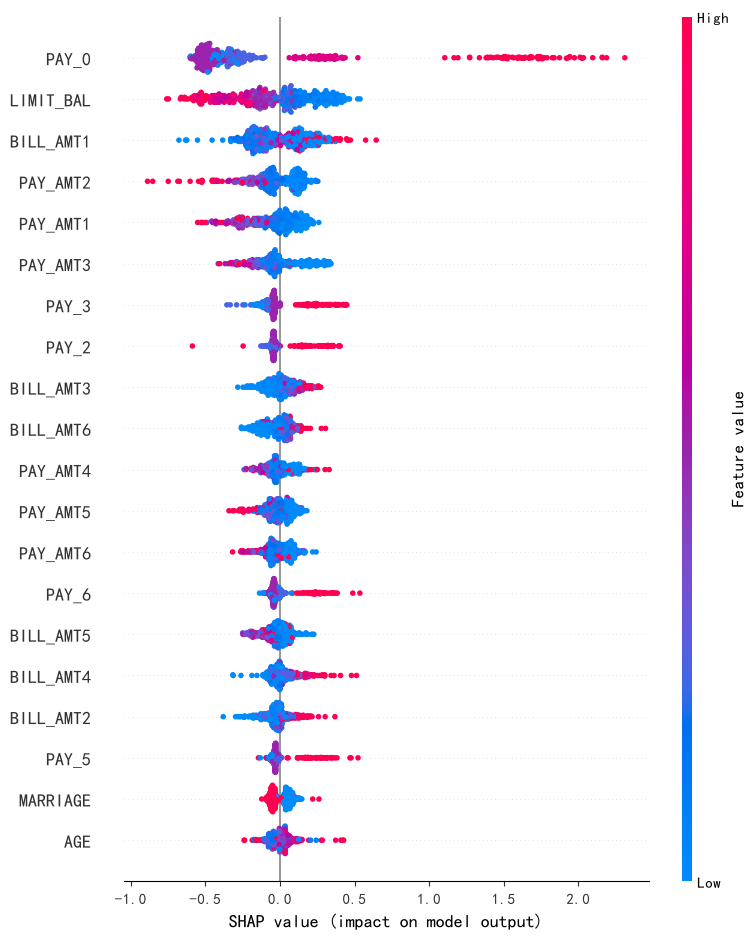

In [40]:
shap.summary_plot(shap_values, X_test.iloc[:500], show=False)
plt.tight_layout()
plt.savefig('shap_summary.png', bbox_inches='tight', dpi=150)
plt.show()

## 9月26日：XGBoost建模与SHAP分析

- 模型：XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1)
- 准确率：81.72%
- AUC：0.776
- 违约类别 F1：0.47（召回率 0.37，需要关注）
- SHAP全局重要性前三：PAY_0、LIMIT_BAL、BILL_AMT1
- SHAP蜂群图核心发现：
  - PAY_0 值高（延迟还款）→ 违约概率大幅升高
  - LIMIT_BAL 值低（额度低）→ 违约概率升高
- 结论：还款状态和信用额度是最核心的预测变量

In [34]:
import numpy as np
y_prob_series = pd.Series(y_prob, index=X_test.index)
high_risk_idx = y_prob_series.sort_values(ascending=False).head(5).index
print("高风险客户索引：", high_risk_idx.tolist())

X_test.loc[high_risk_idx[0]]

高风险客户索引： [16554, 6271, 20721, 29770, 28054]


LIMIT_BAL    10000
SEX              1
EDUCATION        1
MARRIAGE         2
AGE             30
PAY_0            3
PAY_2            2
PAY_3            2
PAY_4            7
PAY_5            7
PAY_6            7
BILL_AMT1     2300
BILL_AMT2     2300
BILL_AMT3     2300
BILL_AMT4     2300
BILL_AMT5     2300
BILL_AMT6     2300
PAY_AMT1         0
PAY_AMT2         0
PAY_AMT3         0
PAY_AMT4         0
PAY_AMT5         0
PAY_AMT6         0
Name: 16554, dtype: int64

In [35]:
import shap
customer_position = X_test.index.get_loc(high_risk_idx[0])

shap.initjs()
shap.force_plot(
    explainer.expected_value,
    shap_values[customer_position],
    X_test.iloc[customer_position]
)

findfont: Failed to find font weight bold, now using 400.


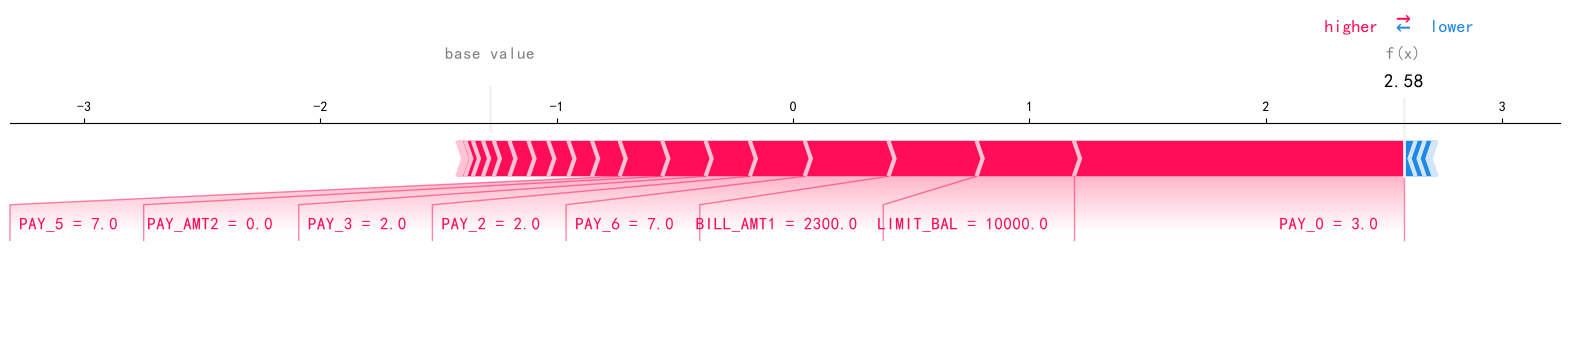

In [36]:
shap.force_plot(
    explainer.expected_value,
    shap_values[customer_position],
    X_test.iloc[customer_position],
    matplotlib=True,
    show=False
)
plt.savefig('shap_force_high_risk.png', bbox_inches='tight')
plt.show()

## 高风险客户SHAP局部解释

### 客户信息

- 客户索引：16554
- 模型预测违约概率：极高（f(x)=2.58，大于0即判定违约）
- 信用额度（LIMIT_BAL）：10,000（远低于均值17.9万）
- 年龄（AGE）：30
- 最近一个月还款状态（PAY_0）：3（延迟3个月）
- 两个月前还款状态（PAY_2）：2（延迟2个月）
- 三个月前还款状态（PAY_3）：2（延迟2个月）
- 半年前还款状态（PAY_6）：7（延迟7个月）
- 过去6个月还款金额（PAY_AMT1~6）：全部为0

### SHAP力导向图解读

力导向图显示，模型从基准值（base value = -1.282）出发，通过多个特征的共同作用，最终将该客户的预测值推向 2.58（判定违约）。

**推高违约概率的特征（红色箭头，按影响从大到小）：**

1. **PAY_0 = 3**：最近一个月延迟3个月还款，是最强的违约推力。
2. **LIMIT_BAL = 10,000**：信用额度极低，是第二强的违约推力。
3. **BILL_AMT1 = 2,300**：账单金额很小，说明消费能力弱。
4. **PAY_6 = 7**：半年前就有延迟7个月的记录，违约行为有历史延续性。
5. **PAY_2 = 2、PAY_3 = 2**：过去几个月持续延迟还款。

**降低违约概率的特征（蓝色箭头）：**

- 影响极微弱，完全被上述红色特征覆盖。

### 业务结论

该客户信用额度仅1万元（远低于均值17.9万），最近一个月延迟3个月还款（PAY_0=3），且过去6个月零还款。SHAP力导向图显示，**PAY_0 和 LIMIT_BAL 是推动模型判定其违约的两个核心因素**。

这说明：**违约预测模型不仅能给出“这个人会违约”的结论，还能明确指出“为什么”——延迟还款和低信用额度是主因。这正是SHAP方法相比传统“黑箱”模型的核心优势。**

In [37]:

y_prob_500 = y_prob[:500]
y_prob_series_500 = pd.Series(y_prob_500, index=X_test.index[:500])
low_risk_idx = y_prob_series_500.sort_values(ascending=True).head(5).index
print("低风险客户索引：", low_risk_idx.tolist())
X_test.loc[low_risk_idx[0]]
customer_position_low = X_test.index.get_loc(low_risk_idx[0])
print("位置：", customer_position_low)
shap.force_plot(
    explainer.expected_value,
    shap_values[customer_position_low],
    X_test.iloc[customer_position_low]
)

低风险客户索引： [29141, 20585, 27602, 16387, 23886]
位置： 197


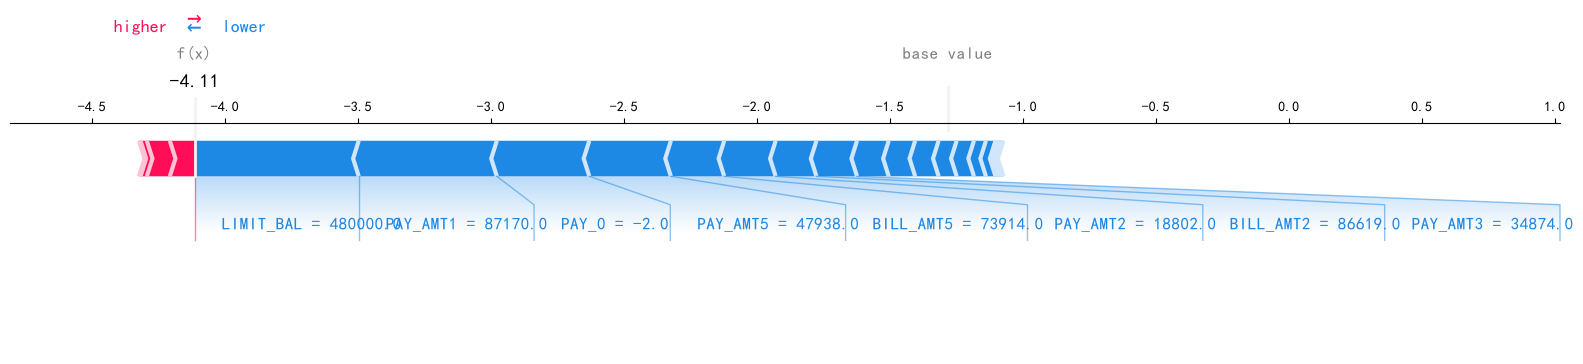

In [38]:
shap.force_plot(
    explainer.expected_value,
    shap_values[customer_position_low],
    X_test.iloc[customer_position_low],
    matplotlib=True,
    show=False
)
plt.savefig('shap_force_low_risk.png', bbox_inches='tight')
plt.show()

## 9月26日：SHAP局部解释与高低风险客户对比

### 高风险客户SHAP局部解释

**客户信息：**
- 客户索引：16554
- 模型预测违约概率：极高（f(x)=2.58，大于0即判定违约）
- 信用额度（LIMIT_BAL）：10,000（远低于均值17.9万）
- 年龄（AGE）：30
- 最近一个月还款状态（PAY_0）：3（延迟3个月）
- 两个月前还款状态（PAY_2）：2（延迟2个月）
- 三个月前还款状态（PAY_3）：2（延迟2个月）
- 半年前还款状态（PAY_6）：7（延迟7个月）
- 过去6个月还款金额（PAY_AMT1~6）：全部为0

**SHAP力导向图解读：**

力导向图显示，模型从基准值（base value = -1.282）出发，通过多个特征的共同作用，最终将该客户的预测值推向 2.58（判定违约）。

推高违约概率的特征（红色箭头，按影响从大到小）：
1. **PAY_0 = 3**：最近一个月延迟3个月还款，是最强的违约推力。
2. **LIMIT_BAL = 10,000**：信用额度极低，是第二强的违约推力。
3. **BILL_AMT1 = 2,300**：账单金额很小，说明消费能力弱。
4. **PAY_6 = 7**：半年前就有延迟7个月的记录，违约行为有历史延续性。
5. **PAY_2 = 2、PAY_3 = 2**：过去几个月持续延迟还款。

降低违约概率的特征（蓝色箭头）：影响极微弱，完全被上述红色特征覆盖。

**业务结论：** 该客户信用额度仅1万元（远低于均值17.9万），最近一个月延迟3个月还款（PAY_0=3），且过去6个月零还款。SHAP力导向图显示，PAY_0 和 LIMIT_BAL 是推动模型判定其违约的两个核心因素。这说明：违约预测模型不仅能给出"这个人会违约"的结论，还能明确指出"为什么"——延迟还款和低信用额度是主因。

---

### 低风险客户SHAP局部解释

**客户信息：**
- 客户索引：29141
- 模型预测违约概率：极低（f(x)=-4.11，远小于0即判定不违约）
- 信用额度（LIMIT_BAL）：4.8e+5（48万，远高于均值17.9万）
- 最近一个月还款状态（PAY_0）：-2（无消费记录）
- 上个月还款金额（PAY_AMT1）：8.7万（大额还款）
- 5个月前还款金额（PAY_AMT5）：4.8万（大额还款）

**SHAP力导向图解读：**

力导向图显示，模型从基准值（base value = -1.282）出发，通过多个特征的共同作用，最终将该客户的预测值推向 -4.11（判定不违约）。

降低违约概率的特征（蓝色箭头，按影响从大到小）：
1. **LIMIT_BAL = 48万**：信用额度极高，是最强的"保护因素"。
2. **PAY_AMT1 = 8.7万**：上个月还款金额巨大。
3. **PAY_AMT5 = 4.8万**：5个月前也有大额还款。
4. **PAY_0 = -2**：无消费记录（不是延迟还款）。

---

### 高低风险客户对比（论文核心论据）

| 维度 | 高风险客户 | 低风险客户 |
|------|-----------|-----------|
| 信用额度 | 1万（极低） | 48万（极高） |
| 还款记录 | 6个月零还款 | 8.7万、4.8万大额还款 |
| PAY_0 | 3（延迟3个月） | -2（无消费） |
| 预测值 f(x) | **+2.58**（违约） | **-4.11**（不违约） |

**两个客户的预测值差距高达 6.69**，SHAP力导向图清晰展示了信用额度和还款行为是决定违约预测的两个核心维度。

**论文核心论点：** 高风险客户信用额度仅1万、连续延迟还款、6个月零还款，模型预测值 +2.58；低风险客户信用额度48万、大额还款记录、无延迟，模型预测值 -4.11。SHAP方法不仅能解释单个预测，还能通过对比揭示模型的决策逻辑——信用额度和还款行为是违约预测的两个核心维度。